In [35]:
# Animated: "A model that gets worse when it gets 'better'"
# Fixes:
#  1) Train/Test samples NEVER disappear during animation (we only update specific traces by index).
#  2) Play/Pause + slider are placed UNDER the figure (in the bottom margin).

import numpy as np
import plotly.graph_objects as go

# -----------------------------
# 1) Data: fixed train/test split
# -----------------------------
rng = np.random.default_rng(3151)

def f_true(x):
    return np.sin(2*np.pi*x)

n_train, n_test = 18, 250
sigma = 0.18

x_train = np.sort(rng.uniform(0, 1, n_train))
y_train = f_true(x_train) + rng.normal(0, sigma, n_train)

x_test = np.sort(rng.uniform(0, 1, n_test))
y_test = f_true(x_test) + rng.normal(0, sigma, n_test)

x_grid = np.linspace(0, 1, 500)
y_grid_true = f_true(x_grid)

# -----------------------------
# 2) Polynomial regression (least squares)
# -----------------------------
def poly_design(x, deg):
    x = np.asarray(x)
    return np.vstack([x**k for k in range(deg + 1)]).T  # [1, x, x^2, ..., x^deg]

def fit_poly(x, y, deg):
    X = poly_design(x, deg)
    w, *_ = np.linalg.lstsq(X, y, rcond=None)
    return w

def predict_poly(w, x):
    deg = len(w) - 1
    return poly_design(x, deg) @ w

def mse(yhat, y):
    e = yhat - y
    return float(np.mean(e * e))

degrees = list(range(0, 21))

pred_grid = []
train_mse = []
test_mse = []

for d in degrees:
    w = fit_poly(x_train, y_train, d)
    pred_grid.append(predict_poly(w, x_grid))

    train_mse.append(mse(predict_poly(w, x_train), y_train))
    test_mse.append(mse(predict_poly(w, x_test), y_test))

best_test_idx = int(np.argmin(test_mse))
best_test_deg = degrees[best_test_idx]

# -----------------------------
# 3) Build figure with persistent traces + animated traces
#    IMPORTANT: we will update ONLY specific traces by index in frames,
#    so the sample points never disappear.
# -----------------------------

# Persistent (static) traces — these should NEVER change / disappear
true_trace = go.Scatter(
    x=x_grid, y=y_grid_true,
    mode="lines",
    name="True f*(x)",
    hoverinfo="skip",
)

train_pts_trace = go.Scatter(
    x=x_train, y=y_train,
    mode="markers",
    name="Train",
    marker=dict(size=8, symbol="circle"),
)

test_pts_trace = go.Scatter(
    x=x_test[::4], y=y_test[::4],   # visual subsample
    mode="markers",
    name="Test (sample)",
    marker=dict(size=6, symbol="x"),
    opacity=0.7,
)

train_mse_curve = go.Scatter(
    x=degrees, y=train_mse,
    mode="lines+markers",
    name="Train MSE",
    xaxis="x2", yaxis="y2",
)

test_mse_curve = go.Scatter(
    x=degrees, y=test_mse,
    mode="lines+markers",
    name="Test MSE",
    xaxis="x2", yaxis="y2",
)

# Animated traces — these WILL be updated each frame
init_i = 0
init_d = degrees[init_i]

model_curve = go.Scatter(
    x=x_grid, y=pred_grid[init_i],
    mode="lines",
    name="Model ŷ(x)",
)

cur_train_marker = go.Scatter(
    x=[init_d], y=[train_mse[init_i]],
    mode="markers",
    name="Current (train)",
    xaxis="x2", yaxis="y2",
    marker=dict(size=14),
)

cur_test_marker = go.Scatter(
    x=[init_d], y=[test_mse[init_i]],
    mode="markers",
    name="Current (test)",
    xaxis="x2", yaxis="y2",
    marker=dict(size=14, symbol="diamond"),
)

# Assemble in a known order so we can reference indices reliably
traces = [
    true_trace,            # idx 0 (static)
    train_pts_trace,       # idx 1 (static)
    test_pts_trace,        # idx 2 (static)
    train_mse_curve,       # idx 3 (static)
    test_mse_curve,        # idx 4 (static)
    model_curve,           # idx 5 (animated)
    cur_train_marker,      # idx 6 (animated)
    cur_test_marker,       # idx 7 (animated)
]

fig = go.Figure(data=traces)

# Helpful static vertical reference line at best test degree (on the right panel)
fig.add_vline(
    x=best_test_deg,
    xref="x2",
    line_width=2,
    opacity=0.6,
)

# -----------------------------
# 4) Frames: update ONLY traces 5, 6, 7 so points never disappear
# -----------------------------
frames = []
for i, d in enumerate(degrees):
    text = (
        f"<b>Degree = {d}</b><br>"
        f"Train MSE = {train_mse[i]:.4f}<br>"
        f"Test MSE = {test_mse[i]:.4f}"
    )
    if d > best_test_deg:
        text += f"<br><span style='font-size:0.95em'>⚠️ Past best test degree ({best_test_deg})</span>"

    frames.append(
        go.Frame(
            name=str(d),
            data=[
                go.Scatter(x=x_grid, y=pred_grid[i]),          # updates trace idx 5
                go.Scatter(x=[d], y=[train_mse[i]]),           # updates trace idx 6
                go.Scatter(x=[d], y=[test_mse[i]]),            # updates trace idx 7
            ],
            traces=[5, 6, 7],  # <-- key line: only update these traces
            layout=go.Layout(
                annotations=[
                    go.layout.Annotation(
                        x=0.02, y=0.98,
                        xref="paper", yref="paper",
                        xanchor="left", yanchor="top",
                        text=text,
                        showarrow=False,
                        align="left",
                        borderwidth=1,
                    )
                ]
            )
        )
    )

fig.frames = frames

# -----------------------------
# 5) Layout: two panels + controls UNDER the figure
# -----------------------------
fig.update_layout(
    title="A model that gets worse when it gets “better”: capacity ↑, train error ↓, test error ↑",
    height=520,

    # Extra bottom margin so slider + buttons sit under the plotting area
    margin=dict(l=40, r=20, t=60, b=140),

    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="left", x=0),

    # Left panel axes
    xaxis=dict(title="x", domain=[0.0, 0.58]),
    yaxis=dict(title="y", domain=[0.0, 1.0]),

    # Right panel axes
    xaxis2=dict(title="Polynomial degree", domain=[0.65, 1.0], anchor="y2"),
    yaxis2=dict(title="MSE", domain=[0.0, 1.0], anchor="x2", rangemode="tozero"),

    # Play/Pause controls UNDER the figure (in bottom margin)
    updatemenus=[
        dict(
            type="buttons",
            direction="left",
            x=0.0, y=-0.22,           # <- under plot
            xanchor="left", yanchor="top",
            pad=dict(r=10, t=10),
            buttons=[
                dict(
                    label="Play",
                    method="animate",
                    args=[None, dict(
                        frame=dict(duration=450, redraw=True),
                        transition=dict(duration=150),
                        fromcurrent=True,
                        mode="immediate",
                    )],
                ),
                dict(
                    label="Pause",
                    method="animate",
                    args=[[None], dict(
                        frame=dict(duration=0, redraw=False),
                        transition=dict(duration=0),
                        mode="immediate",
                    )],
                ),
            ],
        )
    ],

    # Slider just ABOVE the buttons (still under the plot, inside bottom margin)
    sliders=[
        dict(
            active=0,
            x=0.0, y=-0.20,
            xanchor="left",
            len=1.0,
            currentvalue=dict(prefix="Degree: "),
            pad=dict(t=30, b=10),
            steps=[
                dict(
                    method="animate",
                    args=[[str(d)], dict(
                        frame=dict(duration=0, redraw=True),
                        transition=dict(duration=0),
                        mode="immediate",
                    )],
                    label=str(d),
                )
                for d in degrees
            ],
        )
    ],
)

fig.show()

In [36]:
import plotly.graph_objects as go
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial


def generate_data(n, noise=0.1):
    x = rng.uniform(0, 1, size=n)
    y_true = np.sin(2*np.pi*x)
    y = y_true + rng.normal(0, noise, size=n)
    return x, y, y_true

def poly_fit_predict(x_train, y_train, x_grid, degree):
    p = Polynomial.fit(x_train, y_train, degree)
    return p(x_grid)

# One dataset snapshot for visuals
x, y, _ = generate_data(30, noise=0.1)
xg = np.linspace(0, 1, 400)
f_star = np.sin(2*np.pi*xg)


fig = go.Figure()
fig.add_trace(go.Scatter(x=x, y=y, mode="markers", name="samples"))
fig.add_trace(go.Scatter(x=xg, y=f_star, mode="lines", name="f*(x)=sin(2πx)", line=dict(width=4)))

for d in [1,3,5,9]:
    yhat = poly_fit_predict(x, y, xg, d)
    fig.add_trace(go.Scatter(x=xg, y=yhat, mode="lines", name=f"poly degree {d}"))

fig.update_layout(
    title="Toggle model capacity (legend) + hover for values",
    xaxis_title="x",
    yaxis_title="y",
    legend_title="Traces",
    height=520
)
fig.show()

In [37]:
import pandas as pd

def estimate_bias_variance(n_train=30, degree=9, n_reps=200, noise=0.1):
    xg = np.linspace(0, 1, 200)
    f_star = np.sin(2*np.pi*xg)
    preds = []
    for _ in range(n_reps):
        x, y, _ = generate_data(n_train, noise=noise)
        preds.append(poly_fit_predict(x, y, xg, degree))
    preds = np.vstack(preds)  # (reps, grid)
    mean_pred = preds.mean(axis=0)
    bias2 = (mean_pred - f_star)**2
    var = preds.var(axis=0)
    return xg, f_star, mean_pred, bias2, var, preds

rows = []
for d in [1,3,9]:
    xg, f_star, mean_pred, bias2, var, preds = estimate_bias_variance(n_train=30, degree=d, n_reps=200)
    rows.append({
        "degree": d,
        "avg_bias2_over_x": float(bias2.mean()),
        "avg_var_over_x": float(var.mean())
    })

bv = pd.DataFrame(rows).sort_values("degree")
bv

,degree,avg_bias2_over_x,avg_var_over_x
0,1,0.200144,0.018704
1,3,0.004759,0.003126
2,9,0.020274,2.517600


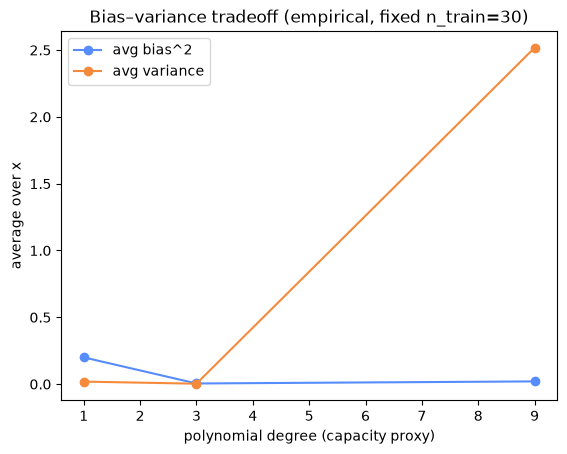

In [38]:
# Visualization: average bias^2 and variance versus degree
plt.figure()
plt.plot(bv["degree"], bv["avg_bias2_over_x"], marker="o", label="avg bias^2")
plt.plot(bv["degree"], bv["avg_var_over_x"], marker="o", label="avg variance")
plt.title("Bias–variance tradeoff (empirical, fixed n_train=30)")
plt.xlabel("polynomial degree (capacity proxy)")
plt.ylabel("average over x")
plt.legend()
plt.show()

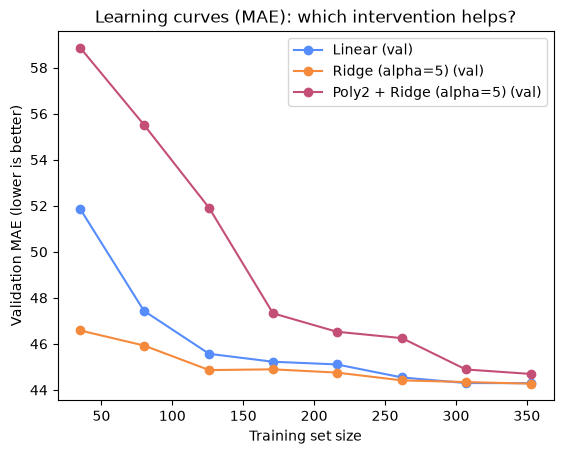

In [39]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import learning_curve, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, make_scorer

X, y = load_diabetes(return_X_y=True)

cv = KFold(n_splits=5, shuffle=True, random_state=0)
mae_scorer = make_scorer(mean_absolute_error, greater_is_better=False)  # sklearn uses higher=better

models = {
    "Linear": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Ridge (alpha=5)": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=5.0))]),
    "Poly2 + Ridge (alpha=5)": Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler(with_mean=False)),
        ("model", Ridge(alpha=5.0))
    ])
}

train_sizes = np.linspace(0.1, 1.0, 8)

plt.figure()
for name, model in models.items():
    sizes, train_scores, val_scores = learning_curve(
        model, X, y, cv=cv, scoring=mae_scorer, train_sizes=train_sizes, n_jobs=None
    )
    train_mae = -train_scores.mean(axis=1)
    val_mae = -val_scores.mean(axis=1)
    plt.plot(sizes, val_mae, marker="o", label=f"{name} (val)")
plt.title("Learning curves (MAE): which intervention helps?")
plt.xlabel("Training set size")
plt.ylabel("Validation MAE (lower is better)")
plt.legend()
plt.show()